# Tic-Tac-Toe: learn to play X
**Companion to _Understanding Reinforcement Learning: Probability and Mathematics
Explained Step by Step_ — Bernd Allmendinger.**

[Open in Google Colab](https://colab.research.google.com/github/berndAllmendinger/understanding-reinforcement-learning/blob/main/notebooks/02_tic_tac_toe.ipynb)
· [Repository](https://github.com/berndAllmendinger/understanding-reinforcement-learning)

## Goal
Watch experience change a table, then play against the result. This notebook is
self-contained: no book files, private data, trained-model download or GPU are needed.
Run the cells **from top to bottom**. In Colab use **Runtime → Run all**.
The final human-play cell is switched off by default so Run all finishes without waiting for input.

The learning path is **Monte Carlo → SARSA → Q-learning → REINFORCE → PPO**.
REINFORCE is the short bridge from learning values to learning action probabilities.
Stop after Q-learning on a first reading; return to PPO later.
Code and explanations use English, like the book. A German upload guide accompanies the repository.

**Read the results honestly.** We train against a fixed opponent. A high training score
is not proof of perfect play against a human. The final checks make this distinction visible.
These are new teaching runs, not a reproduction of the exact printed v21 parameter settings.
The prepared repository links above become active after publication under the stated name.

## 1. Setup and the meaning of the symbols
We use NumPy for arrays and random draws, pandas for readable tables and Matplotlib for one plot.
These are available in a normal Colab runtime; the repository also provides local requirements.

| Symbol / code | Meaning | Role |
|---|---|---|
| $S_t$, `state` after observation | Situation immediately before **our** move | Random before observation; a known value afterwards |
| $A_t$, `action` | Our chosen legal move | Random under exploration; an observed label in a record |
| $R_{t+1}$, `reward` | Score paid by the environment after this transition | Random before the transition |
| $G_t$, `target` in MC | Sum of rewards from this decision to the end | Random future return; calculable after the game |
| $\widehat Q(s,a)$, `q[state][action-1]` | Estimated expected return after choosing $a$ | Learned table entry, **not a probability** |
| $\theta(s,a)$, `preferences` | Scores used by a policy's softmax | Learned parameters |
| $\widehat V(s)$, `values` | Critic's estimate of return from a state | Learned parameter |
| $\alpha$, $\gamma$, $\epsilon$ | Step size, discount and exploration rate | Settings chosen by us, not learned |

For a fixed policy $\pi$ and fixed environment,
$Q^\pi(s,a)=\mathbb E_\pi[G_t\mid S_t=s,A_t=a]$ is a definite mathematical number.
Different random training histories produce different estimates $\widehat Q$ of such numbers.
Once a training run is fixed, its saved table is a definite array.
Here $\gamma=1$ because each game ends after a bounded number of moves.

In [1]:
import sys
import copy
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
GAMMA = 1.0                 # Finite games: no discounting in this notebook.
EPISODES = 20000            # Change this, then rerun the training cells.
ALPHA = 0.15               # Step size for SARSA and Q-learning.
PPO_BATCH_SIZE = 100
PPO_BATCHES = 200           # 100 * 200 = 20,000 games.
PPO_EPOCHS = 4
CLIP = 0.2
ACTOR_STEP = 1.0
CRITIC_STEP = 1.0
CHECKPOINTS = {0, 1000, EPISODES}

plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11})
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
print('Python', sys.version.split()[0], '| NumPy', np.__version__)

Python 3.9.13 | NumPy 1.21.6


## 2. The environment supplies the rules
The learner is always **X and moves first**; the fixed training opponent is O,
choosing uniformly among empty squares. Three Xs in a row/column/diagonal win;
three Os lose; a full board without a line is a draw. Stop immediately at the result.

A state is a tuple of nine entries: $0$ empty, $1$ X, $-1$ O, read row by row.
Only X-turn states enter our learned table. The player is implicit in that convention.
Labels **1–9** name squares; Python array indices are **0–8**, hence `action - 1`.
The action mask excludes occupied squares. It comes from the rules, not learning.
`XX./OO./...` is a compact printout of one complete board, not an extra hidden feature.

One transition combines X's move and, if needed, O's reply. It ends at the next
X turn or a terminal result. Reward is $+1$ for an X win, $-1$ for an O win,
$0$ for a draw or an unfinished transition. The `done` flag distinguishes those last two cases.
Before a reply is observed, its conditional probability is
$p(O\text{ chooses }b\mid\text{board after X})=1/|\mathcal A(\text{board after X})|$.
This is an environment probability; the learner estimates values or its own action probabilities.

In [2]:
ACTION_COUNT = 9
TRAIN_OPPONENT = 'random'
EMPTY_BOARD = (0,) * 9
EXAMPLE_STATE = (1, 1, 0, -1, -1, 0, 0, 0, 0)
DISPLAY_STATES = [EMPTY_BOARD, (1, -1, 0, 0, 0, 0, 0, 0, 0), EXAMPLE_STATE]
WINNING_LINES = [(0,1,2), (3,4,5), (6,7,8), (0,3,6), (1,4,7), (2,5,8),
                 (0,4,8), (2,4,6)]

def result(board):
    for i, j, k in WINNING_LINES:
        if board[i] != 0 and board[i] == board[j] == board[k]:
            return board[i]       # +1: X wins; -1: O wins.
    return 0 if 0 not in board else None  # 0: draw; None: unfinished.

def legal_actions(state):
    if result(state) is not None:
        return []
    return [i + 1 for i, mark in enumerate(state) if mark == 0]

def place(board, action, player):
    if action not in legal_actions(board):
        raise ValueError('Choose an empty square in an unfinished game.')
    updated = list(board)
    updated[action - 1] = player
    return tuple(updated)         # Tuples can be dictionary keys.

def start_state(rng):
    return EMPTY_BOARD            # Learner X always starts; human will be O.

def state_label(state):
    symbols = {0: '.', 1: 'X', -1: 'O'}
    rows = [''.join(symbols[v] for v in state[i:i+3]) for i in (0,3,6)]
    return '/'.join(rows)

def show_state(state):
    cells = [str(i+1) if v == 0 else ('X' if v == 1 else 'O')
             for i, v in enumerate(state)]
    print('\n---------\n'.join(' | '.join(cells[i:i+3]) for i in (0,3,6)))

### Complete a transition
The opponent function includes an optional perfect opponent for later checks.
Its `minimax` helper is defined only in the evaluation section; training uses random replies.

In [3]:
def opponent_action(board, rng, opponent):
    actions = legal_actions(board)
    if opponent == 'random':
        return int(rng.choice(actions))
    if opponent == 'perfect':
        # Used only in evaluation, AFTER the learning functions have run.
        scores = [minimax(place(board, a, -1), 1) for a in actions]
        return actions[int(np.argmin(scores))]  # O minimises X's result.
    raise ValueError('Unknown opponent')

def step(state, action, rng, opponent=TRAIN_OPPONENT):
    after_x = place(state, action, 1)
    score = result(after_x)
    if score is not None:
        return None, float(score), True
    reply = opponent_action(after_x, rng, opponent)
    after_o = place(after_x, reply, -1)
    score = result(after_o)
    if score is not None:
        return None, float(score), True
    return after_o, 0.0, False  # Both moves belong to ONE learning transition.

## 3. Make the table visible before learning
`q` is a dictionary: one state points to one short NumPy row. This is still a Q-table.
Unseen entries start at zero, a neutral **initial estimate**, not evidence of a draw.
Illegal entries are displayed as `illegal` and excluded from action selection and targets.
If several legal entries tie, the smallest action label wins the tie.
Comparisons use unrounded numbers; four printed decimals can hide a small difference.

An $\epsilon$-greedy policy explores uniformly with probability $\epsilon$; otherwise
it takes a largest entry. The exploration branch can also pick the greedy action.
We decrease $\epsilon$ linearly and keep a floor of 0.05. This finite teaching schedule
and a constant TD step size do **not** establish a convergence theorem.

There are many board states, so the table below shows **three explicitly listed boards**,
not the entire state space. Later you can change the board list or print a chosen slice.
Before training every possible board row is implicitly zero; we store rows when encountered.

In [4]:
def q_row(table, state):
    # An unseen state has initial estimates zero; reading does not train it.
    return table.get(state, np.zeros(ACTION_COUNT))

def ensure_row(table, state):
    if state not in table:
        table[state] = np.zeros(ACTION_COUNT)
    return table[state]

def greedy_action(table, state):
    actions = legal_actions(state)
    values = [q_row(table, state)[a - 1] for a in actions]
    # np.argmax returns the FIRST maximum: smallest legal action breaks ties.
    return actions[int(np.argmax(values))]

def show_table(table, states=DISPLAY_STATES, selected=None, probabilities=False, title=None):
    rows = []
    for state in states:
        row = []
        for action in range(1, ACTION_COUNT + 1):
            if action not in legal_actions(state):
                row.append('illegal')
            else:
                prefix = '* ' if selected == (state, action) else ''
                row.append(prefix + f'{q_row(table, state)[action-1]:.4f}')
        rows.append(row)
    frame = pd.DataFrame(rows, index=[state_label(s) for s in states],
                         columns=[f'action {a}' for a in range(1, ACTION_COUNT+1)])
    frame.index.name = 'state (learner to move)'
    print(title or ('Action probabilities' if probabilities else 'Estimated Q-values'))
    print('Each row = one state. Each column = one action. * = selected cell.')
    display(frame)
    return frame

def exploration_rate(episode, total):
    return max(0.05, 1.0 - episode / (0.8 * total))

def epsilon_action(table, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.choice(legal_actions(state)))
    return greedy_action(table, state)

def discounted_returns(records):
    returns = []
    future = 0.0
    for state, action, reward, next_state, done in reversed(records):
        future = reward + GAMMA * future
        returns.append(future)
    return list(reversed(returns))

show_state(EXAMPLE_STATE)
initial_q = {}
_ = show_table(initial_q)

X | X | 3
---------
O | O | 6
---------
7 | 8 | 9
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
XO./.../...,illegal,illegal,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
XX./OO./...,illegal,illegal,0.0000,illegal,illegal,0.0000,0.0000,0.0000,0.0000


## 4. A record is an observation; a target is a calculation
Each record stores `(state, action, reward, next_state, done)`.
The input is the observed state. The action tells a Q learner **which output cell** to fit.
The immediate reward is what really happened on this transition; it is never overwritten
by a later outcome. `None` marks the terminal next state; it is not a playable state.

The return identity is $G_t=R_{t+1}+\gamma G_{t+1}$, with future return zero after termination.
To compute a complete observed return, start at the end and apply this identity backwards.
The following is a **constructed teaching episode**, not a claim about the last random training game.

In [5]:
board_1 = (1, 0, 0, -1, 0, 0, 0, 0, 0)  # X1, O4.
board_2 = (1, 1, 0, -1, -1, 0, 0, 0, 0) # Then X2, O5.
teaching_records = [(EMPTY_BOARD, 1, 0.0, board_1, False),
                    (board_1, 2, 0.0, board_2, False),
                    (board_2, 3, 1.0, None, True)]
teaching_returns = discounted_returns(teaching_records)
rows = [(state_label(s), a, r, state_label(ns) if ns else 'terminal', d, g)
        for (s,a,r,ns,d), g in zip(teaching_records, teaching_returns)]
display(pd.DataFrame(rows, columns=['state','action','reward','next state','done','MC target G']))
print('X wins across the top row. Returns backwards: 1, then 0+1, then 0+1.')

,state,action,reward,next state,done,MC target G
0,.../.../...,1,0.0,X../O../...,False,1.0
1,X../O../...,2,0.0,XX./OO./...,False,1.0
2,XX./OO./...,3,1.0,terminal,True,1.0


X wins across the top row. Returns backwards: 1, then 0+1, then 0+1.


With $\gamma=1$ and only a terminal score, all three **MC targets** happen to equal 1.
The recorded rewards remain **0, 0, 1**. With $\gamma<1$, earlier targets would differ.
Q-learning instead uses $r+\gamma\max\widehat Q(s',\cdot)$, not the observed complete return.
The final real reward enters its terminal update and can influence earlier estimates through
later updates. A zero immediate reward is not the same as a missing training target.

## 5. Monte Carlo control: wait, compute a return, average
For a particular state/action pair, let $N$ be its updated visit count. Its running mean is
$$\widehat Q_{\rm new}(s,a)=\widehat Q_{\rm old}(s,a)
  +\frac{G_t-\widehat Q_{\rm old}(s,a)}{N}.$$
Why? The old sum is $(N-1)\widehat Q_{\rm old}$. Add $G_t$, divide by $N$, then rearrange.
Example: after returns $1,-1$, the mean is 0. A third return 1 gives
$(1-1+1)/3=1/$\{1,2,3\}$, equivalently $0+(1-0)/$\{1,2,3\}$.
We average sampled returns to estimate their conditional mean, not to change the rewards.

This is **control**: behaviour uses the table and exploration, so the policy changes.
Earlier and later returns may come from different continuation policies. The table is not
an exact evaluation of one fixed final policy. No state repeats within one of these games,
so first-visit and every-visit MC coincide here. Unvisited pairs learn nothing.
This is Monte Carlo **learning from games**, not Monte Carlo tree search.

In [6]:
def train_mc(episodes=EPISODES, seed=SEED):
    rng = np.random.default_rng(seed)
    q, counts = {}, {}
    snapshots, scores = {0: {}}, []
    for episode in range(1, episodes + 1):
        epsilon = exploration_rate(episode, episodes)
        state, records = start_state(rng), []
        while state is not None:
            action = epsilon_action(q, state, epsilon, rng)
            next_state, reward, done = step(state, action, rng)
            records.append((state, action, reward, next_state, done))
            state = next_state
        # Only now is the complete return known for every recorded decision.
        for record, target in zip(records, discounted_returns(records)):
            state, action, reward, next_state, done = record
            count = ensure_row(counts, state)
            count[action - 1] += 1
            row = ensure_row(q, state)
            row[action - 1] += (target - row[action - 1]) / count[action - 1]
        scores.append(sum(record[2] for record in records))
        if episode in CHECKPOINTS or episode == episodes:
            snapshots[episode] = copy.deepcopy(q)
    return q, snapshots, scores

mc_q, mc_snapshots, mc_scores = train_mc()
_ = show_table(mc_q)

Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.4863,0.4715,0.5146,0.4440,0.8607,0.4357,0.5099,0.3973,0.5569
XO./.../...,illegal,illegal,0.1875,0.4706,0.5000,0.5000,0.7400,0.4286,0.5455
XX./OO./...,illegal,illegal,1.0000,illegal,illegal,0.5000,0.3333,-0.3333,0.0000


## 6. SARSA: learn from the next action actually selected
$$y_t=r_{t+1}+\gamma\widehat Q(s_{t+1},a_{t+1}),\qquad
\widehat Q(s_t,a_t)\leftarrow\widehat Q(s_t,a_t)+\alpha[y_t-\widehat Q(s_t,a_t)].$$
At a terminal transition set $y_t=r_{t+1}$: there is no next action.
First choose $a_{t+1}$ with the current exploratory rule, read its estimated value,
form the target, subtract our old estimate and add a fraction $\alpha$ of that difference.
SARSA includes the effects of its exploratory next choice. Only one visited cell is updated.

In [7]:
def train_sarsa(episodes=EPISODES, seed=SEED):
    rng = np.random.default_rng(seed)
    q, snapshots, scores = {}, {0: {}}, []
    for episode in range(1, episodes + 1):
        epsilon = exploration_rate(episode, episodes)
        state = start_state(rng)
        action = epsilon_action(q, state, epsilon, rng)
        total = 0.0
        while state is not None:
            next_state, reward, done = step(state, action, rng)
            target = reward
            next_action = None
            if not done:
                next_action = epsilon_action(q, next_state, epsilon, rng)
                target += GAMMA * q_row(q, next_state)[next_action - 1]
            row = ensure_row(q, state)
            row[action - 1] += ALPHA * (target - row[action - 1])
            state, action = next_state, next_action
            total += reward
        scores.append(total)
        if episode in CHECKPOINTS or episode == episodes:
            snapshots[episode] = copy.deepcopy(q)
    return q, snapshots, scores

sarsa_q, sarsa_snapshots, sarsa_scores = train_sarsa()
_ = show_table(sarsa_q)

Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.4563,0.4724,0.5704,0.4179,0.9187,0.3699,0.5799,0.6138,0.7278
XO./.../...,illegal,illegal,-0.0159,-0.0067,0.1131,0.0183,0.4432,0.0132,0.1317
XX./OO./...,illegal,illegal,0.9369,illegal,illegal,0.0087,0.1071,-0.3859,0.0000


## 7. Q-learning: use the largest legal next estimate
The Bellman optimality equation **for this fixed-opponent environment** is
$$Q^*(s,a)=\mathbb E[R_{t+1}+\gamma\max_{b\in\mathcal A(S_{t+1})}Q^*(S_{t+1},b)
  \mid S_t=s,A_t=a].$$
It is an exact relationship between unknown optimal values. To learn without an explicit
transition-probability table, take one observed transition and use current estimates:
$$y_t=r_{t+1}+\gamma\max_{b\in\mathcal A(s_{t+1})}\widehat Q(s_{t+1},b),$$
$$\widehat Q_{\rm new}(s_t,a_t)=\widehat Q_{\rm old}(s_t,a_t)
    +\alpha[y_t-\widehat Q_{\rm old}(s_t,a_t)].$$
At termination the continuation term is zero. The inner maximum contains the expected
**remaining** outcome in the next state, not just the next reward. No search is performed
when the trained agent compares a row. Future consequences entered the row through learning.
Replacing the expectation by a sample gives a learning rule; it is not an equality for each sample.

### One update, with all numbers visible
These starting estimates are deliberately set for a hand calculation.
They are independent of the real training run below. The asterisk marks the one changed cell.

In [8]:
hand_q = {EXAMPLE_STATE: np.array([0., 0., 0.4, 0., 0., 0., 0., 0., 0.])}
state, action = EXAMPLE_STATE, 3
_ = show_table(hand_q, [state], (state, action))
next_state, reward, done = step(state, action, np.random.default_rng(0))
old, alpha = hand_q[state][action-1], 0.25
target = reward  # Terminal win: NO next-state value to add.
error = target-old
correction = alpha*error
hand_q[state][action-1] = old+correction
print(f'Reward = {reward}, done = {done}, target = {target}')
print(f'Error = 1 - 0.4 = {error:.2f}')
print(f'Correction = 0.25 * 0.6 = {correction:.2f}')
print(f'New Q = 0.4 + 0.15 = {hand_q[state][action-1]:.2f}')
_ = show_table(hand_q, [state], (state, action))

Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
XX./OO./...,illegal,illegal,* 0.4000,illegal,illegal,0.0000,0.0000,0.0000,0.0000


Reward = 1.0, done = True, target = 1.0
Error = 1 - 0.4 = 0.60
Correction = 0.25 * 0.6 = 0.15
New Q = 0.4 + 0.15 = 0.55
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
XX./OO./...,illegal,illegal,* 0.5500,illegal,illegal,0.0000,0.0000,0.0000,0.0000


### Train a fresh Q-table
The trainer begins at zero; it does not use the hand calculation or an exact solver.

In [9]:
def train_q_learning(episodes=EPISODES, seed=SEED):
    rng = np.random.default_rng(seed)
    q, snapshots, scores = {}, {0: {}}, []
    for episode in range(1, episodes + 1):
        epsilon = exploration_rate(episode, episodes)
        state, total = start_state(rng), 0.0
        while state is not None:
            action = epsilon_action(q, state, epsilon, rng)
            next_state, reward, done = step(state, action, rng)
            target = reward
            if not done:
                best_next = greedy_action(q, next_state)
                target += GAMMA * q_row(q, next_state)[best_next - 1]
            row = ensure_row(q, state)
            row[action - 1] += ALPHA * (target - row[action - 1])
            state = next_state
            total += reward
        scores.append(total)
        if episode in CHECKPOINTS or episode == episodes:
            snapshots[episode] = copy.deepcopy(q)
    return q, snapshots, scores

q_table, q_snapshots, q_scores = train_q_learning()
_ = show_table(q_table)

Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.6301,0.5422,0.7464,0.7103,0.6833,0.5383,0.9879,0.7247,0.6036
XO./.../...,illegal,illegal,0.0569,0.0358,0.0525,0.0321,0.1250,0.0407,0.5603
XX./OO./...,illegal,illegal,0.9126,illegal,illegal,0.0934,0.0416,-0.4780,0.0000


## 8. A policy table is different from a Q-table
A policy directly learns probabilities $\pi_\theta(a\mid s)$, short for
$\Pr_\theta(A_t=a\mid S_t=s)$. A score $\theta(s,a)$ is an adjustable parameter.
Convert legal scores into probabilities by the softmax:
$$\pi_\theta(a\mid s)=\frac{e^{\theta(s,a)}}{\sum_{b\in\mathcal A(s)}e^{\theta(s,b)}}.$$
Illegal actions have probability zero. Legal probabilities sum to one.
Zero preferences give a uniform legal policy; they do not give zero probability.
The code subtracts the largest score before exponentiating. This cancels from numerator
and denominator and avoids unnecessarily large exponentials.

For one score in a row, differentiating the log probability gives
$$\frac{\partial\log\pi_\theta(a\mid s)}{\partial\theta(s,b)}
   =\mathbf1\{b=a\}-\pi_\theta(b\mid s).$$
Here the indicator is 1 when $b=a$, otherwise 0. Differentiate
$\theta(s,a)-\log\sum_b e^{\theta(s,b)}$: the first term gives the indicator;
the log-sum term gives the probability by the chain rule. All other states' scores stay fixed.
The vector in code simply collects these partial derivatives.

In [10]:
def policy_probabilities(preferences, state):
    actions = legal_actions(state)
    logits = q_row(preferences, state)[np.array(actions) - 1]
    weights = np.exp(logits - np.max(logits))  # Stable, equivalent softmax.
    row = np.zeros(ACTION_COUNT)
    row[np.array(actions) - 1] = weights / weights.sum()
    return row

def policy_episode(preferences, rng):
    state, records = start_state(rng), []
    while state is not None:
        probabilities = policy_probabilities(preferences, state)
        action = int(rng.choice(np.arange(1, ACTION_COUNT+1), p=probabilities))
        next_state, reward, done = step(state, action, rng)
        records.append((state, action, reward, next_state, done))
        state = next_state
    return records

def log_probability_gradient(probabilities, action):
    gradient = -probabilities.copy()
    gradient[action - 1] += 1.0
    return gradient

def probability_table(preferences, states):
    return {s: policy_probabilities(preferences, s) for s in states}

_ = show_table(probability_table({}, DISPLAY_STATES), probabilities=True)

Action probabilities
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.1111,0.1111,0.1111,0.1111,0.1111,0.1111,0.1111,0.1111,0.1111
XO./.../...,illegal,illegal,0.1429,0.1429,0.1429,0.1429,0.1429,0.1429,0.1429
XX./OO./...,illegal,illegal,0.2000,illegal,illegal,0.2000,0.2000,0.2000,0.2000


## 9. REINFORCE: the bridge to PPO
For each decision in a completed game, update its policy scores by
$$\theta(s,b)\leftarrow\theta(s,b)+\eta G_t
  [\mathbf1\{b=a_t\}-\pi_\theta(b\mid s)].$$
$\eta=0.08$ is the actor step size. With $\gamma=1$, the terminal return is the
episode's score at every earlier decision. Positive returns push the sampled actions up;
negative returns push them down. Other legal probabilities adjust because they must sum to one.
This is a sample policy-gradient update, not proof that every selected action deserved all the credit.
Averaging many games matters. No Q-table is learned by this method.

In [11]:
def train_reinforce(episodes=EPISODES, seed=SEED):
    rng = np.random.default_rng(seed)
    preferences, scores = {}, []
    snapshots = {0: {}}
    for episode in range(1, episodes + 1):
        records = policy_episode(preferences, rng)
        # A state cannot repeat in either game, so these rows are distinct.
        for record, target in zip(records, discounted_returns(records)):
            state, action, reward, next_state, done = record
            probabilities = policy_probabilities(preferences, state)
            gradient = log_probability_gradient(probabilities, action)
            ensure_row(preferences, state)[:] += 0.08 * target * gradient
        scores.append(sum(record[2] for record in records))
        if episode in CHECKPOINTS or episode == episodes:
            snapshots[episode] = copy.deepcopy(preferences)
    return preferences, snapshots, scores

reinforce_preferences, reinforce_snapshots, reinforce_scores = train_reinforce()
_ = show_table(probability_table(reinforce_preferences, DISPLAY_STATES),
               probabilities=True)

Action probabilities
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.0002,0.0001,0.0003,0.0001,0.9983,0.0001,0.0004,0.0002,0.0002
XO./.../...,illegal,illegal,0.1457,0.1349,0.1461,0.1459,0.1349,0.1349,0.1576
XX./OO./...,illegal,illegal,0.2000,illegal,illegal,0.2000,0.2000,0.2000,0.2000


## 10. PPO, one idea at a time
This is **tabular PPO-Clip with a Monte Carlo advantage**: it implements the clipped
objective, repeated updates on one batch, and a learned critic. It is not a neural-network
or full production implementation. There is no GAE, entropy bonus or advantage normalisation.

**First collect games with a frozen old policy.** For each record compute
$$\widehat A_t=G_t-\widehat V_{\rm old}(s_t),\qquad
\rho_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\rm old}(a_t\mid s_t)}.$$
The advantage asks whether this outcome exceeded the old state's predicted return.
It is an estimate, not the exact theoretical advantage. Save $G_t$, the old probability
and $\widehat A_t$; keep them fixed during every epoch on this batch.

**Then improve the current policy with a clipped objective.** For one record,
$$\ell_t(\theta)=\min\bigl(\rho_t\widehat A_t,
\operatorname{clip}(\rho_t,1-c,1+c)\widehat A_t\bigr),\qquad c=0.2.$$
`clip` limits a number to the stated interval. If $\widehat A_t>0$ and $\rho_t>1.2$,
the minimum is the constant $1.2\widehat A_t$: this record gives no further actor gradient.
If $\widehat A_t<0$ and $\rho_t<0.8$, the clipped branch is again constant.
In the active branch the derivative is $\rho_t\widehat A_t$
times the log-probability derivative already derived. Clipping is **not** a hard bound
on every eventual probability change; other records can also move the parameters.

We maximise the **mean over games of each game's summed record objectives**.
Divide the summed gradients by the number of games, not by the number of records.
The critic minimises the corresponding mean of $\tfrac12(G_t-\widehat V(s_t))^2$.
Its negative derivative is $G_t-\widehat V(s_t)$, which explains the positive critic correction.

In [12]:
# A separate two-action numerical example, not a fitted game row.
old_probability, advantage, actor_step = 0.5, 1.0, 0.2
probabilities = np.array([0.5, 0.5])
ratio = probabilities[0] / old_probability
gradient = ratio * advantage * (np.array([1., 0.]) - probabilities)
new_scores = actor_step * gradient
new_probabilities = np.exp(new_scores) / np.exp(new_scores).sum()
print('Ratio = 0.5/0.5 =', ratio)
print('Gradient = 1 * 1 * ([1, 0] - [0.5, 0.5]) =', gradient)
print('New scores = 0.2 * gradient =', new_scores)
print('New probabilities =', new_probabilities.round(4))
print('Clipped positive example: min(1.4*1, 1.2*1) =', min(1.4, 1.2))
print('Clipped negative example: min(0.7*(-1), 0.8*(-1)) =', min(-0.7, -0.8))

Ratio = 0.5/0.5 = 1.0
Gradient = 1 * 1 * ([1, 0] - [0.5, 0.5]) = [ 0.5 -0.5]
New scores = 0.2 * gradient = [ 0.1 -0.1]
New probabilities = [0.5498 0.4502]
Clipped positive example: min(1.4*1, 1.2*1) = 1.2
Clipped negative example: min(0.7*(-1), 0.8*(-1)) = -0.8


### Collect fixed records and apply one PPO epoch
`batch_size` counts games.
We accumulate all corrections first so a batch reads one consistent current parameter version.

In [13]:
def collect_ppo_batch(preferences, values, rng, batch_size):
    batch, scores = [], []
    # No parameters change while we collect these games.
    for _ in range(batch_size):
        records = policy_episode(preferences, rng)
        for record, target in zip(records, discounted_returns(records)):
            state, action, reward, next_state, done = record
            old_probability = policy_probabilities(preferences, state)[action - 1]
            advantage = target - values.get(state, 0.0)
            # These five quantities stay FIXED throughout all PPO epochs.
            batch.append((state, action, target, old_probability, advantage))
        scores.append(sum(record[2] for record in records))
    return batch, scores

def ppo_epoch(preferences, values, batch, batch_size):
    actor_gradients, critic_changes = {}, {}
    for state, action, target, old_probability, advantage in batch:
        probabilities = policy_probabilities(preferences, state)
        ratio = probabilities[action - 1] / old_probability
        clipped_flat = ((advantage > 0 and ratio > 1 + CLIP) or
                        (advantage < 0 and ratio < 1 - CLIP))
        if not clipped_flat:
            gradient = log_probability_gradient(probabilities, action)
            ensure_row(actor_gradients, state)[:] += ratio * advantage * gradient
        critic_changes[state] = critic_changes.get(state, 0.0) + target - values.get(state, 0.0)
    # Apply accumulated gradients together, not part-way through a batch.
    for state, gradient in actor_gradients.items():
        ensure_row(preferences, state)[:] += ACTOR_STEP * gradient / batch_size
    for state, change in critic_changes.items():
        values[state] = values.get(state, 0.0) + CRITIC_STEP * change / batch_size

### Inspect an actual PPO batch record
The following two new demonstration games use the initial uniform policy.
The old state values are zero. We print the state input, chosen action, computed return,
old action probability and advantage. These are the records used by `ppo_epoch`;
the immediate rewards remain in the original episodes and are not replaced by the return.

In [14]:
demo_batch, demo_scores = collect_ppo_batch({}, {}, np.random.default_rng(2026), 2)
demo_rows = [(state_label(s), a, g, old_p, advantage)
             for s, a, g, old_p, advantage in demo_batch]
display(pd.DataFrame(demo_rows, columns=['state input', 'action', 'return target G',
                                       'old action probability', 'advantage G - old V']))
demo_preferences, demo_values = {}, {}
ppo_epoch(demo_preferences, demo_values, demo_batch, batch_size=2)
demo_states = list(dict.fromkeys(row[0] for row in demo_batch))
_ = show_table(probability_table(demo_preferences, demo_states), demo_states,
               probabilities=True, title='Probabilities after one demonstration PPO epoch')

,state input,action,return target G,old action probability,advantage G - old V
0,.../.../...,2,1.0,0.111111,1.0
1,OX./.../...,6,1.0,0.142857,1.0
2,OX./..X/O..,4,1.0,0.200000,1.0
3,OX./X.X/OO.,9,1.0,0.333333,1.0
4,OXO/X.X/OOX,5,1.0,1.000000,1.0
5,.../.../...,2,1.0,0.111111,1.0
6,.X./.../.O.,4,1.0,0.142857,1.0
7,.X./X.O/.O.,9,1.0,0.200000,1.0
8,.X./XOO/.OX,3,1.0,0.333333,1.0
9,.XX/XOO/OOX,1,1.0,1.000000,1.0


Probabilities after one demonstration PPO epoch
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.0933,0.2536,0.0933,0.0933,0.0933,0.0933,0.0933,0.0933,0.0933
OX./.../...,illegal,illegal,0.1307,0.1307,0.1307,0.2156,0.1307,0.1307,0.1307
OX./..X/O..,illegal,illegal,0.1770,0.2919,0.1770,illegal,illegal,0.1770,0.1770
OX./X.X/OO.,illegal,illegal,0.2741,illegal,0.2741,illegal,illegal,illegal,0.4519
OXO/X.X/OOX,illegal,illegal,illegal,illegal,1.0000,illegal,illegal,illegal,illegal
.X./.../.O.,0.1307,illegal,0.1307,0.2156,0.1307,0.1307,0.1307,illegal,0.1307
.X./X.O/.O.,0.1770,illegal,0.1770,illegal,0.1770,illegal,0.1770,illegal,0.2919
.X./XOO/.OX,0.2741,illegal,0.4519,illegal,illegal,illegal,0.2741,illegal,illegal
.XX/XOO/OOX,1.0000,illegal,illegal,illegal,illegal,illegal,illegal,illegal,illegal


### Repeat with fresh batches
One epoch is one optimisation pass over the same collected batch.
An episode is one played game. They are different counters. Four epochs do not mean four new games.

In [15]:
def train_ppo(batches=PPO_BATCHES, batch_size=PPO_BATCH_SIZE, seed=SEED):
    rng = np.random.default_rng(seed)
    preferences, values, scores = {}, {}, []
    snapshots = {0: {}}
    for batch_number in range(1, batches + 1):
        batch, batch_scores = collect_ppo_batch(preferences, values, rng, batch_size)
        for _ in range(PPO_EPOCHS):
            ppo_epoch(preferences, values, batch, batch_size)
        scores.extend(batch_scores)
        episode = batch_number * batch_size
        if episode in CHECKPOINTS or batch_number == batches:
            snapshots[episode] = copy.deepcopy(preferences)
    return preferences, values, snapshots, scores

ppo_preferences, ppo_values, ppo_snapshots, ppo_scores = train_ppo()
_ = show_table(probability_table(ppo_preferences, DISPLAY_STATES), probabilities=True)
display(pd.DataFrame({'state': [state_label(s) for s in DISPLAY_STATES],
                      'critic V estimate': [ppo_values.get(s, 0.0) for s in DISPLAY_STATES]}))

Action probabilities
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.0049,0.0004,0.0022,0.0003,0.9894,0.0007,0.0009,0.0003,0.0009
XO./.../...,illegal,illegal,0.1349,0.1466,0.1870,0.1327,0.1268,0.1417,0.1303
XX./OO./...,illegal,illegal,0.2367,illegal,illegal,0.2008,0.2008,0.1846,0.1771


,state,critic V estimate
0,.../.../...,0.500000
1,XO./.../...,0.599596
2,XX./OO./...,-0.050859


## 11. Choose a method and a saved table
Change `METHOD` and `SNAPSHOT` below, then rerun this cell.
Q methods display values; policy methods display **probabilities**, not renamed Q-values.
Snapshots are independent copies: the initial table does not silently change during training.
A deterministic policy player selects its largest probability. Setting `sample_policy=True`
samples from the learned probabilities instead. Those are different deployment rules.

In [16]:
models = {'Monte Carlo': ('q', mc_q), 'SARSA': ('q', sarsa_q),
          'Q-learning': ('q', q_table), 'REINFORCE': ('policy', reinforce_preferences),
          'PPO': ('policy', ppo_preferences)}
all_snapshots = {'Monte Carlo': mc_snapshots, 'SARSA': sarsa_snapshots,
                 'Q-learning': q_snapshots, 'REINFORCE': reinforce_snapshots,
                 'PPO': ppo_snapshots}

def agent_action(name, state, rng, sample_policy=False):
    kind, table = models[name]
    if kind == 'q':
        return greedy_action(table, state)
    probabilities = policy_probabilities(table, state)
    if sample_policy:
        return int(rng.choice(np.arange(1, ACTION_COUNT+1), p=probabilities))
    return greedy_action({state: probabilities}, state)

METHOD = 'Q-learning'  # Choose any key printed below.
SNAPSHOT = EPISODES   # 0 = before training; 1000 = intermediate; EPISODES = final.
print('Methods:', list(models))
print('Available snapshots:', sorted(all_snapshots[METHOD]))
selected_table = all_snapshots[METHOD][SNAPSHOT]
is_policy = models[METHOD][0] == 'policy'
if is_policy:
    selected_table = probability_table(selected_table, DISPLAY_STATES)
_ = show_table(selected_table, probabilities=is_policy)

Methods: ['Monte Carlo', 'SARSA', 'Q-learning', 'REINFORCE', 'PPO']
Available snapshots: [0, 1000, 20000]
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.6301,0.5422,0.7464,0.7103,0.6833,0.5383,0.9879,0.7247,0.6036
XO./.../...,illegal,illegal,0.0569,0.0358,0.0525,0.0321,0.1250,0.0407,0.5603
XX./OO./...,illegal,illegal,0.9126,illegal,illegal,0.0934,0.0416,-0.4780,0.0000


### Inspect any stored board row
Choose a slice of the full learned Q-table. The stored rows are
encountered boards, not all possible positions. `XX./OO./...` is always an X-turn board here.

In [17]:
FIRST_ROW = 0
NUMBER_OF_ROWS = 8
all_stored_boards = sorted(q_table, key=state_label)
print('Stored board rows:', len(all_stored_boards))
boards_to_show = all_stored_boards[FIRST_ROW:FIRST_ROW+NUMBER_OF_ROWS]
_ = show_table(q_table, boards_to_show)
# Or supply your own reachable X-turn board, e.g. [EXAMPLE_STATE].

Stored board rows: 2400
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.6301,0.5422,0.7464,0.7103,0.6833,0.5383,0.9879,0.7247,0.6036
.../.../.OX,0.1997,0.0093,0.2457,0.0249,0.6452,0.1577,0.0647,illegal,illegal
.../.../.XO,0.0328,0.0013,0.0137,0.0109,0.6195,0.0312,0.0173,illegal,illegal
.../.../O.X,0.4205,0.0240,0.1001,0.0119,0.1095,0.1928,illegal,0.0114,illegal
.../.../OX.,0.0161,0.1129,0.0287,0.0160,0.5491,0.0202,illegal,illegal,0.0181
.../.../X.O,0.4830,0.4991,0.6791,0.9998,0.7702,0.3519,illegal,0.3862,illegal
.../.../XO.,0.7310,0.4018,0.7890,0.9714,0.9993,0.2592,illegal,illegal,0.3177
.../..O/..X,0.3788,0.0364,0.0190,0.0107,0.6154,illegal,0.1208,0.0802,illegal


## 12. Checks: freeze learning and test the result
Evaluation does not update tables, run exploration or feed test outcomes back into training.
The random stream for tests is separate. In the table below, the score is
$(\text{wins}-\text{losses})/\text{games}$, estimating expected terminal reward.
It is not generally the win rate because draws and losses have different effects.
Training scores include exploratory actions, while greedy deployment does not.

The exact solver is defined **only now**, after all training calls. It is a checking tool,
not an input or target supplied to the learners. A perfect-play opponent uses game-tree
reasoning; our trained agents only read their current rows.

In [18]:
@lru_cache(None)
def minimax(board, player):
    score = result(board)
    if score is not None:
        return score
    scores = [minimax(place(board, a, player), -player) for a in legal_actions(board)]
    return max(scores) if player == 1 else min(scores)

def worst_case_score(name, start):
    @lru_cache(None)
    def value(board):
        action = agent_action(name, board, np.random.default_rng(0))
        after_x = place(board, action, 1)
        score = result(after_x)
        if score is not None:
            return score
        replies = []
        for reply in legal_actions(after_x):
            after_o = place(after_x, reply, -1)
            score = result(after_o)
            replies.append(score if score is not None else value(after_o))
        return min(replies)  # Adversary exploits THIS frozen learner.
    return value(start)

EVALUATION_START = EMPTY_BOARD
EVALUATION_OPPONENTS = ['random', 'perfect']
print('Perfect play from the empty board:', minimax(EMPTY_BOARD, 1), '(draw)')

Perfect play from the empty board: 0 (draw)


In [19]:
def evaluate(name, opponent, games=500, seed=1007, sample_policy=False):
    rng = np.random.default_rng(seed)  # Separate evaluation random stream.
    wins = draws = losses = 0
    for _ in range(games):
        state = EVALUATION_START
        while state is not None:
            action = agent_action(name, state, rng, sample_policy)
            state, reward, done = step(state, action, rng, opponent)
        wins += reward == 1
        draws += reward == 0
        losses += reward == -1
    return {'method': name, 'opponent': opponent,
            'selection': 'sampled policy' if sample_policy else 'largest value/probability',
            'wins': wins, 'draws': draws, 'losses': losses,
            'mean score': (wins-losses)/games}

evaluation_rows = []
for name, (kind, _) in models.items():
    for opponent in EVALUATION_OPPONENTS:
        evaluation_rows.append(evaluate(name, opponent))
    if kind == 'policy':
        evaluation_rows.append(evaluate(name, TRAIN_OPPONENT, sample_policy=True))
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.round(3))
print('500 fresh games per row; counts are observations, not guarantees.')

,method,opponent,selection,wins,draws,losses,mean score
0,Monte Carlo,random,largest value/probability,487,7,6,0.962
1,Monte Carlo,perfect,largest value/probability,0,0,500,-1.000
2,SARSA,random,largest value/probability,494,6,0,0.988
3,SARSA,perfect,largest value/probability,0,500,0,0.000
4,Q-learning,random,largest value/probability,490,10,0,0.980
5,Q-learning,perfect,largest value/probability,0,500,0,0.000
6,REINFORCE,random,largest value/probability,488,12,0,0.976
7,REINFORCE,perfect,largest value/probability,0,500,0,0.000
8,REINFORCE,random,sampled policy,444,29,27,0.834
9,PPO,random,largest value/probability,493,7,0,0.986


500 fresh games per row; counts are observations, not guarantees.


### An exact check against an adversary
A finite batch of games can miss a weakness. The next check considers **every possible
opponent reply**, recursively, with our trained deterministic policy held fixed.
It returns the worst terminal score the opponent can force. This is stronger than
playing a particular tie-breaking perfect opponent in a few test games.
The adversary may exploit mistakes specific to our frozen learner.

In [20]:
rows = [{'method': name, 'worst-case score from empty board': worst_case_score(name, EMPTY_BOARD)}
        for name in models]
display(pd.DataFrame(rows))
print('-1: some opponent sequence wins. 0: the greedy agent guarantees at least a draw.')
print('+1 would mean a forced win; that is impossible from an empty board against perfect play.')
print('These exact checks concern largest-value/probability deployment, not policy sampling.')

,method,worst-case score from empty board
0,Monte Carlo,-1
1,SARSA,0
2,Q-learning,-1
3,REINFORCE,0
4,PPO,0


-1: some opponent sequence wins. 0: the greedy agent guarantees at least a draw.
+1 would mean a forced win; that is impossible from an empty board against perfect play.
These exact checks concern largest-value/probability deployment, not policy sampling.


Perfect Tic-Tac-Toe is a draw. A score of 0 in the exact worst-case check means
our frozen greedy X player cannot be beaten from the empty board. A score of $-1$
identifies a possible loss even if most random test opponents lose.
Learning against random replies does not directly optimise worst-case play.
Sparse visits, finite training and policy approximation can leave weaknesses.
The table reports what happened; no method is declared optimal simply because of its name.

### See the training history
Each line is one seeded run, smoothed over 500 games.
This is a teaching diagnostic, **not** a multi-seed ranking or a matched-computation benchmark.
PPO reuses each batch four times; methods need not perform equal amounts of computation.

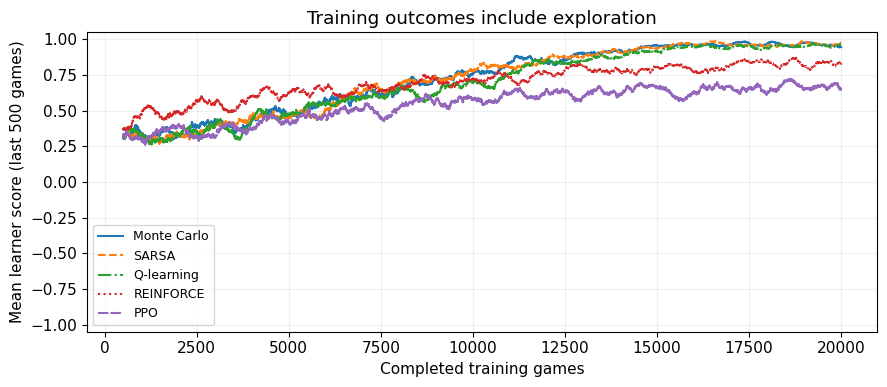

In [21]:
training_scores = {'Monte Carlo': mc_scores, 'SARSA': sarsa_scores,
                   'Q-learning': q_scores, 'REINFORCE': reinforce_scores, 'PPO': ppo_scores}
fig, ax = plt.subplots()
styles = ['-', '--', '-.', ':', (0, (5, 1))]
for (name, scores), style in zip(training_scores.items(), styles):
    window = min(500, len(scores))
    means = pd.Series(scores).rolling(window).mean()
    ax.plot(np.arange(1, len(scores)+1), means, label=name, linestyle=style)
ax.set(xlabel='Completed training games', ylabel='Mean learner score (last 500 games)',
       ylim=(-1.05, 1.05), title='Training outcomes include exploration')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 13. Play one complete frozen game
The marked cell explains the next action.
No learning occurs. Change the method to replay with a different learned table.

In [22]:
def show_game(name='Q-learning', opponent=TRAIN_OPPONENT):
    rng = np.random.default_rng(1234)
    board = EMPTY_BOARD
    while True:
        action = agent_action(name, board, rng)
        kind, table = models[name]
        shown = probability_table(table, [board]) if kind == 'policy' else table
        show_table(shown, [board], (board, action), kind == 'policy')
        print('Agent X chooses', action)
        board = place(board, action, 1)
        show_state(board)
        if result(board) is not None:
            break
        reply = opponent_action(board, rng, opponent)
        print('Opponent O chooses', reply)
        board = place(board, reply, -1)
        show_state(board)
        if result(board) is not None:
            break
        print('Reward = 0; next learner decision follows.')
    print('Terminal reward from X perspective:', result(board))

show_game('Q-learning')

Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../...,0.6301,0.5422,0.7464,0.7103,0.6833,0.5383,* 0.9879,0.7247,0.6036


Agent X chooses 7
1 | 2 | 3
---------
4 | 5 | 6
---------
X | 8 | 9
Opponent O chooses 9
1 | 2 | 3
---------
4 | 5 | 6
---------
X | 8 | O
Reward = 0; next learner decision follows.
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../.../X.O,0.4830,0.4991,0.6791,* 0.9998,0.7702,0.3519,illegal,0.3862,illegal


Agent X chooses 4
1 | 2 | 3
---------
X | 5 | 6
---------
X | 8 | O
Opponent O chooses 8
1 | 2 | 3
---------
X | 5 | 6
---------
X | O | O
Reward = 0; next learner decision follows.
Estimated Q-values
Each row = one state. Each column = one action. * = selected cell.


,action 1,action 2,action 3,action 4,action 5,action 6,action 7,action 8,action 9
state (learner to move),,,,,,,,,
.../X../XOO,* 1.0000,0.5121,0.3888,illegal,0.1627,0.4825,illegal,illegal,illegal


Agent X chooses 1
X | 2 | 3
---------
X | 5 | 6
---------
X | O | O
Terminal reward from X perspective: 1


## 14. Your turn: play against the trained agent
Set `PLAY = True`, choose `PLAY_METHOD`, and run the next cell.
Use the input field below the cell; enter `q` to stop. Illegal entries are rejected.
You are a new opponent, so the agent may encounter positions or replies it practised rarely.
The printed values still refer to its training environment, not to a model of your personal strategy.

In [23]:
def play_human(name='Q-learning', sample_policy=False):
    rng = np.random.default_rng(2026)
    board = EMPTY_BOARD
    print('Agent = X (starts). You = O. Type q to stop.')
    while True:
        action = agent_action(name, board, rng, sample_policy)
        kind, table = models[name]
        shown = probability_table(table, [board]) if kind == 'policy' else table
        show_table(shown, [board], (board, action), kind == 'policy')
        print('Agent chooses square', action)
        board = place(board, action, 1)
        show_state(board)
        if result(board) is not None:
            break
        while True:
            raw = input(f'Your square {legal_actions(board)}: ').strip().lower()
            if raw == 'q':
                return
            if raw.isdigit() and int(raw) in legal_actions(board):
                break
            print('Choose an empty square.')
        board = place(board, int(raw), -1)
        show_state(board)
        if result(board) is not None:
            break
    print({1: 'Agent wins.', -1: 'You win!', 0: 'Draw.'}[result(board)])

PLAY = False             # Change to True and run THIS cell to play.
PLAY_METHOD = 'Q-learning'
if PLAY:
    play_human(PLAY_METHOD, sample_policy=False)
else:
    print('Ready: set PLAY = True. The trained agent always plays X in this example.')

Ready: set PLAY = True. The trained agent always plays X in this example.


## 15. Small experiments and reproducibility
1. Compare the zero table, 1,000 games and the final table. Which rows were updated?
2. Reduce `EPISODES` and PPO's total batch games. Rerun from setup. Do rare states remain inaccurate?
3. Change `SEED`, run everything again and compare. One seed cannot establish a method ranking.
4. Compare greedy policy deployment with sampling. Inspect the probabilities to explain a surprise.
5. Change the opponent only as a separate experiment, then retrain and compare on a fixed test protocol.

The supported walkthrough fixes $\gamma=1$. Changing it changes the meaning of values;
the policy-gradient weighting and exact reference checks would also need review.
Numerical hand examples are labelled separately from fitted results. All game data are
generated by the visible rules; there are no external training files, credentials or uploads.
The examples deliberately keep the learner in one player role and use a fixed training opponent.
Self-play with a changing opponent would change the learning problem and requires extra bookkeeping.

**Connection to the book.** Monte Carlo and TD: Chapters 12–14; SARSA and Q-learning:
Chapters 17–18; direct policy learning and PPO: Chapters 23–25; games: Chapter 26.
Read a formula as: inputs → computed target → changed parameter → later decision.

**Further reading.** Sutton & Barto, _Reinforcement Learning: An Introduction_, second edition,
[author's book page](http://incompleteideas.net/book/the-book-2nd.html), Chapters 5, 6 and 13.
Schulman et al. (2017), [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347).
The implementations and examples here are original companion teaching code, not copied figures or library internals.

Code and companion explanations: MIT, see repository `LICENSE`.
Book cover and book manuscript are excluded; see `ASSET_RIGHTS.md`.